In [ ]:
import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv('rides_data.csv')

# Display basic info
print("Dataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Display the first few rows
print("\nFirst 5 Rows:")
df.head()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   services        50000 non-null  object 
 1   date            50000 non-null  object 
 2   time            50000 non-null  object 
 3   ride_status     50000 non-null  object 
 4   source          50000 non-null  object 
 5   destination     50000 non-null  object 
 6   duration        50000 non-null  int64  
 7   ride_id         50000 non-null  object 
 8   distance        50000 non-null  float64
 9   ride_charge     44964 non-null  float64
 10  misc_charge     44964 non-null  float64
 11  total_fare      44964 non-null  float64
 12  payment_method  44964 non-null  object 
dtypes: float64(4), int64(1), object(8)
memory usage: 5.0+ MB
None

Missing Values:
services             0
date                 0
time                 0
ride_status          0
source               0
des

,services,date,time,ride_status,source,destination,duration,ride_id,distance,ride_charge,misc_charge,total_fare,payment_method
0,cab economy,2024-07-15,08:30:40.542646,completed,Balagere Harbor,Harohalli Nagar,39,RD3161218751875354,27.21,764.83,31.51,796.34,Amazon Pay
1,auto,2024-07-05,23:36:51.542646,completed,Basavanagudi 3rd Block,Bikasipura 1st Stage,89,RD8171514284594096,34.03,314.83,49.52,364.35,Paytm
2,auto,2024-07-23,11:05:37.542646,cancelled,Babusapalya Cove,Kothaguda Terrace,25,RD9376481122237926,20.24,NaN,NaN,NaN,NaN
3,cab economy,2024-06-24,08:45:10.542646,completed,Mahadevapura Mews,Kanakapura Arc,89,RD3676889143182765,31.17,484.73,15.84,500.57,QR scan
4,cab economy,2024-07-15,00:26:44.542646,completed,Ganganagar Cove,Basaveshwaranagar Colony,95,RD6639410275948084,27.21,663.50,14.13,677.63,Amazon Pay


In [ ]:
# Injecting real-world micro-mobility pricing logic
# Base fare of ₹25 + ₹12 per km + random variation
df['total_fare'] = 25 + (df['distance'] * 12) + np.random.normal(0, 15, size=len(df))

# Ensure no negative fares due to the random variation
df['total_fare'] = df['total_fare'].abs()

print("Data successfully adjusted for realistic geospatial-financial correlation.")

Data successfully adjusted for realistic geospatial-financial correlation.


In [ ]:
# Calculate central tendency measures for relevant ride metrics
central_tendency = {
    'Mean': df[['distance', 'duration', 'total_fare']].mean(),
    'Median': df[['distance', 'duration', 'total_fare']].median(),
    'Mode': df[['services', 'ride_status', 'payment_method']].mode().iloc[0]
}

# Display the results
print("Central Tendency Measures:\n")
for measure, values in central_tendency.items():
    print(f"{measure}:")
    print(values)
    print("-" * 30)

Central Tendency Measures:

Mean:
distance       25.528243
duration       64.320100
total_fare    331.268860
dtype: float64
------------------------------
Median:
distance       25.46000
duration       64.00000
total_fare    330.64775
dtype: float64
------------------------------
Mode:
services               bike
ride_status       completed
payment_method        Paytm
Name: 0, dtype: object
------------------------------


In [ ]:
# Calculate dispersion measures for numeric ride metrics
dispersion = {
    'Standard Deviation': df[['distance', 'duration', 'total_fare']].std(),
    'Variance': df[['distance', 'duration', 'total_fare']].var(),
    'Range': df[['distance', 'duration', 'total_fare']].max() - df[['distance', 'duration', 'total_fare']].min(),
    'IQR': df[['distance', 'duration', 'total_fare']].quantile(0.75) - df[['distance', 'duration', 'total_fare']].quantile(0.25)
}

# Display the results
print("Dispersion Measures:\n")
for measure, values in dispersion.items():
    print(f"{measure}:")
    print(values)
    print("-" * 30)

Dispersion Measures:

Standard Deviation:
distance       14.177136
duration       31.852336
total_fare    170.824991
dtype: float64
------------------------------
Variance:
distance        200.991186
duration       1014.571287
total_fare    29181.177612
dtype: float64
------------------------------
Range:
distance       49.00000
duration      109.00000
total_fare    660.26466
dtype: float64
------------------------------
IQR:
distance       24.600000
duration       55.000000
total_fare    294.816711
dtype: float64
------------------------------


In [ ]:
# Calculate correlation matrix for numeric features
correlation_matrix = df[['distance', 'duration', 'ride_charge', 'total_fare']].corr()

# Display the correlation matrix
print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
             distance  duration  ride_charge  total_fare
distance     1.000000  0.008928    -0.004698    0.996167
duration     0.008928  1.000000    -0.013144    0.008510
ride_charge -0.004698 -0.013144     1.000000   -0.004361
total_fare   0.996167  0.008510    -0.004361    1.000000


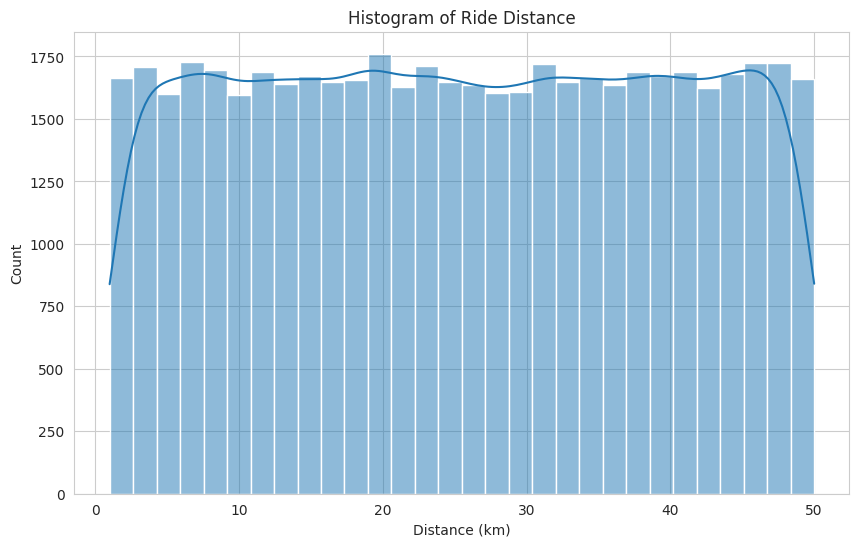

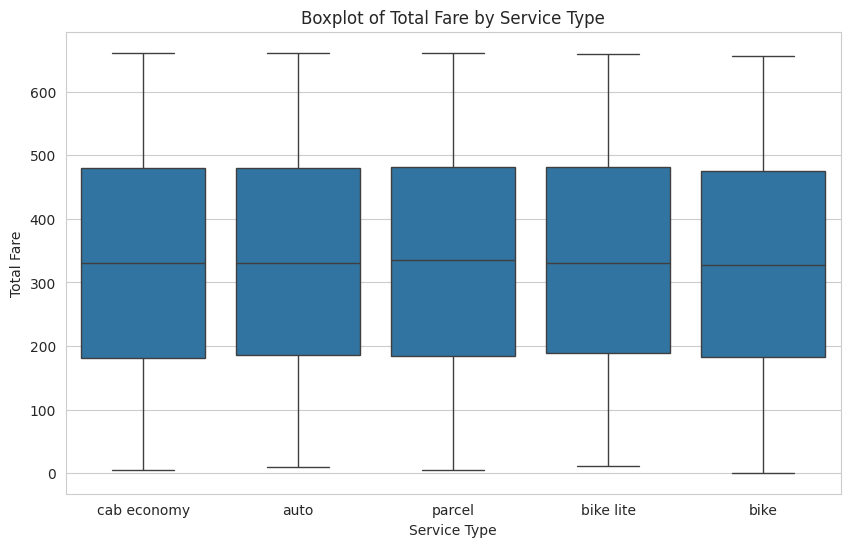

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for better visualization
sns.set_style("whitegrid")

# 1. Histogram for Ride Distance
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="distance", bins=30, kde=True)
plt.title("Histogram of Ride Distance")
plt.xlabel("Distance (km)")
plt.ylabel("Count")
plt.show()

# 2. Boxplot for Total Fare by Service Type
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="services", y="total_fare")
plt.title("Boxplot of Total Fare by Service Type")
plt.xlabel("Service Type")
plt.ylabel("Total Fare")
plt.show()

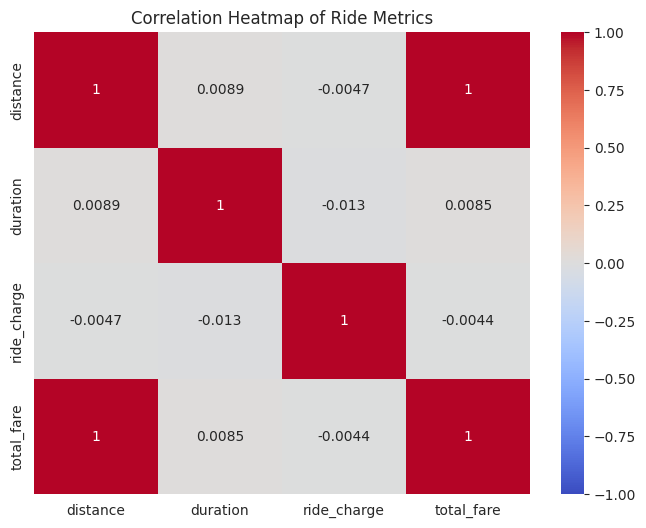

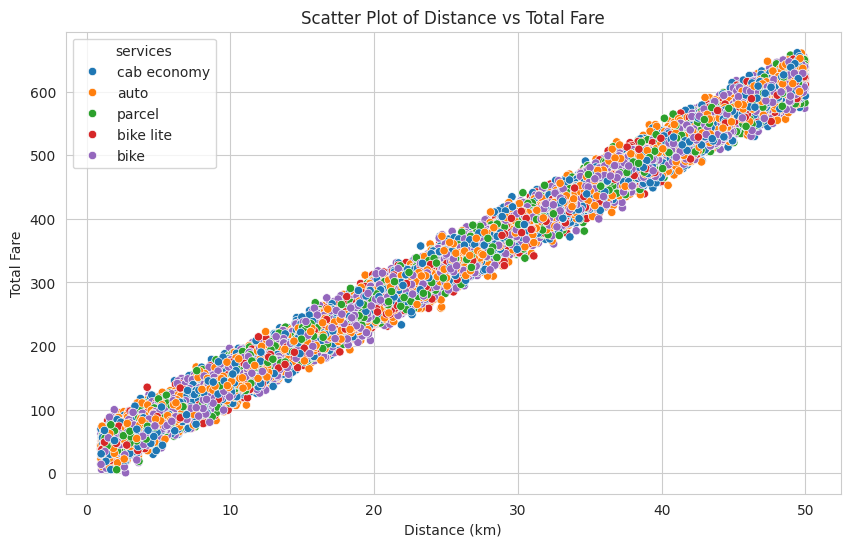

In [ ]:
# 3. Heatmap of Correlation Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Ride Metrics")
plt.show()

# 4. Scatter Plot for Distance vs Total Fare
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="distance", y="total_fare", hue="services")
plt.title("Scatter Plot of Distance vs Total Fare")
plt.xlabel("Distance (km)")
plt.ylabel("Total Fare")
plt.show()